# GOES SEP Monitoring, February 2026 to present

Downloads GOES primary 5-minute solar particle flux data from the NASA
ISWA/CCMC HAPI server and plots it at 1-hour cadence, to identify when
solar energetic particle (SEP) events occur.


In [1]:
import io
import time
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd
import requests
from pathlib import Path
import numpy as np

In [2]:
# ---------------------------------------------------------------- settings
DATASET_ID = "goesp_part_flux_P5M"   # GOES primary, 5-minute particle flux (ISWA HAPI)
START = pd.Timestamp("2026-02-01", tz="UTC")
END = pd.Timestamp.now(tz="UTC").floor("5min")
CHUNK_DAYS = 7                        # size of each download request
PLOT_COLS = ["P10"]                   # channel(s) to plot (see printed column list)

OUT_DIR = Path(r"C:\Users\pauls\SEPs\IMAP\data\GOES")   # or Path.home() / "goes_data"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_CSV = OUT_DIR / "goes_primary_5min_2026-02_to_now.csv"
HOURLY_CSV = OUT_DIR / "goes_primary_1h_2026-02_to_now.csv"

BASE = "https://iswa.ccmc.gsfc.nasa.gov/hapi"


In [3]:
# ---------------------------------------------------------------- metadata
def get_info(dataset_id):
    """Ask the server which columns the dataset has, and what its fill values are."""
    r = requests.get(f"{BASE}/info", params={"id": dataset_id}, timeout=60)
    r.raise_for_status()
    return r.json()


info = get_info(DATASET_ID)
params_meta = info["parameters"]               # first entry is Time
columns = [p["name"] for p in params_meta]
fills = {p["name"]: p.get("fill") for p in params_meta[1:]}

print("Columns available:", columns)
print("Coverage according to server:",
      info.get("startDate"), "->", info.get("stopDate"))

Columns available: ['Time', 'P1', 'P5', 'P10', 'P30', 'P50', 'P100', 'E_8', 'E2_0', 'E4_0', 'P60', 'P500', 'satelliteElectron', 'satelliteProton']
Coverage according to server: 2010-04-14T00:00:00Z -> 2026-10-28T10:00:00Z


In [4]:
# ---------------------------------------------------------------- download
CHUNK_DIR = OUT_DIR / "chunks"
CHUNK_DIR.mkdir(parents=True, exist_ok=True)


def fetch_chunk(t0, t1, retries=5):
    """Return CSV text for the interval, or None if the server has no data."""
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(
                f"{BASE}/data",
                params={
                    "id": DATASET_ID,
                    "time.min": t0.strftime("%Y-%m-%dT%H:%M:%SZ"),
                    "time.max": t1.strftime("%Y-%m-%dT%H:%M:%SZ"),
                    "format": "csv",
                },
                timeout=(10, 300),            # (connect, read) seconds
            )
            if r.status_code == 404:          # HAPI: no data in this interval
                return None
            r.raise_for_status()
            return r.text
        except (requests.exceptions.ConnectionError,
                requests.exceptions.Timeout,
                requests.exceptions.HTTPError) as e:
            wait = 5 * 2 ** (attempt - 1)     # 5, 10, 20, 40, 80 s
            print(f"  attempt {attempt}/{retries} failed ({type(e).__name__}); "
                  f"retrying in {wait}s")
            time.sleep(wait)
    raise RuntimeError(f"Giving up on {t0:%Y-%m-%d} -> {t1:%Y-%m-%d}")


def download(start, end):
    frames = []
    t0 = start
    while t0 < end:
        t1 = min(t0 + timedelta(days=CHUNK_DAYS), end)
        cache = CHUNK_DIR / f"{t0:%Y%m%d}.csv"
        complete = t1 < end                   # last chunk is partial, don't cache it

        if complete and cache.exists():
            frames.append(pd.read_csv(cache, header=None, names=columns))
            print(f"  cached {t0:%Y-%m-%d} -> {t1:%Y-%m-%d}")
        else:
            text = fetch_chunk(t0, t1)
            if text is None:
                print(f"  no data {t0:%Y-%m-%d} -> {t1:%Y-%m-%d}")
            elif text.strip():
                frame = pd.read_csv(io.StringIO(text), comment="#",
                                    header=None, names=columns)
                frames.append(frame)
                if complete:
                    frame.to_csv(cache, header=False, index=False)
                print(f"  got {len(frame):5d} rows "
                      f"{t0:%Y-%m-%d} -> {t1:%Y-%m-%d}")
            time.sleep(1)
        t0 = t1
    return pd.concat(frames, ignore_index=True)


df = download(START, END)

  cached 2026-02-01 -> 2026-02-08
  cached 2026-02-08 -> 2026-02-15
  cached 2026-02-15 -> 2026-02-22
  cached 2026-02-22 -> 2026-03-01
  cached 2026-03-01 -> 2026-03-08
  cached 2026-03-08 -> 2026-03-15
  cached 2026-03-15 -> 2026-03-22
  cached 2026-03-22 -> 2026-03-29
  cached 2026-03-29 -> 2026-04-05
  cached 2026-04-05 -> 2026-04-12
  cached 2026-04-12 -> 2026-04-19
  cached 2026-04-19 -> 2026-04-26
  cached 2026-04-26 -> 2026-05-03
  cached 2026-05-03 -> 2026-05-10
  cached 2026-05-10 -> 2026-05-17
  cached 2026-05-17 -> 2026-05-24
  cached 2026-05-24 -> 2026-05-31
  cached 2026-05-31 -> 2026-06-07
  cached 2026-06-07 -> 2026-06-14
  cached 2026-06-14 -> 2026-06-21
  cached 2026-06-21 -> 2026-06-28
  cached 2026-06-28 -> 2026-07-05
  cached 2026-07-05 -> 2026-07-12
  cached 2026-07-12 -> 2026-07-19
  cached 2026-07-19 -> 2026-07-26
  cached 2026-07-26 -> 2026-08-02
  cached 2026-08-02 -> 2026-08-09
  cached 2026-08-09 -> 2026-08-16
  cached 2026-08-16 -> 2026-08-23
  cached 2026-

In [5]:
# ---------------------------------------------------------------- clean
time_col = columns[0]
df[time_col] = pd.to_datetime(df[time_col], utc=True)
for c in columns[1:]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    fill = fills[c]
    if fill is None or str(fill).strip().lower() in ("null", "nan", ""):
        continue                               # no numeric fill value to replace
    try:
        df.loc[df[c] == float(fill), c] = float("nan")
    except ValueError:
        print(f"  skipping fill replacement for {c}: unusable fill {fill!r}")

df = (df.drop_duplicates(time_col)
        .sort_values(time_col)
        .set_index(time_col))
df.index.name = "Time"

df.to_csv(RAW_CSV)
print(f"Saved 5-min data ({len(df)} rows) to {RAW_CSV}")


Saved 5-min data (77477 rows) to C:\Users\pauls\SEPs\IMAP\data\GOES\goes_primary_5min_2026-02_to_now.csv


In [6]:
# ---------------------------------------------------------------- 1-hour cadence
hourly = df.resample("1h").mean()
hourly.to_csv(HOURLY_CSV)
print(f"Saved hourly data ({len(hourly)} rows) to {HOURLY_CSV}")


Saved hourly data (6467 rows) to C:\Users\pauls\SEPs\IMAP\data\GOES\goes_primary_1h_2026-02_to_now.csv


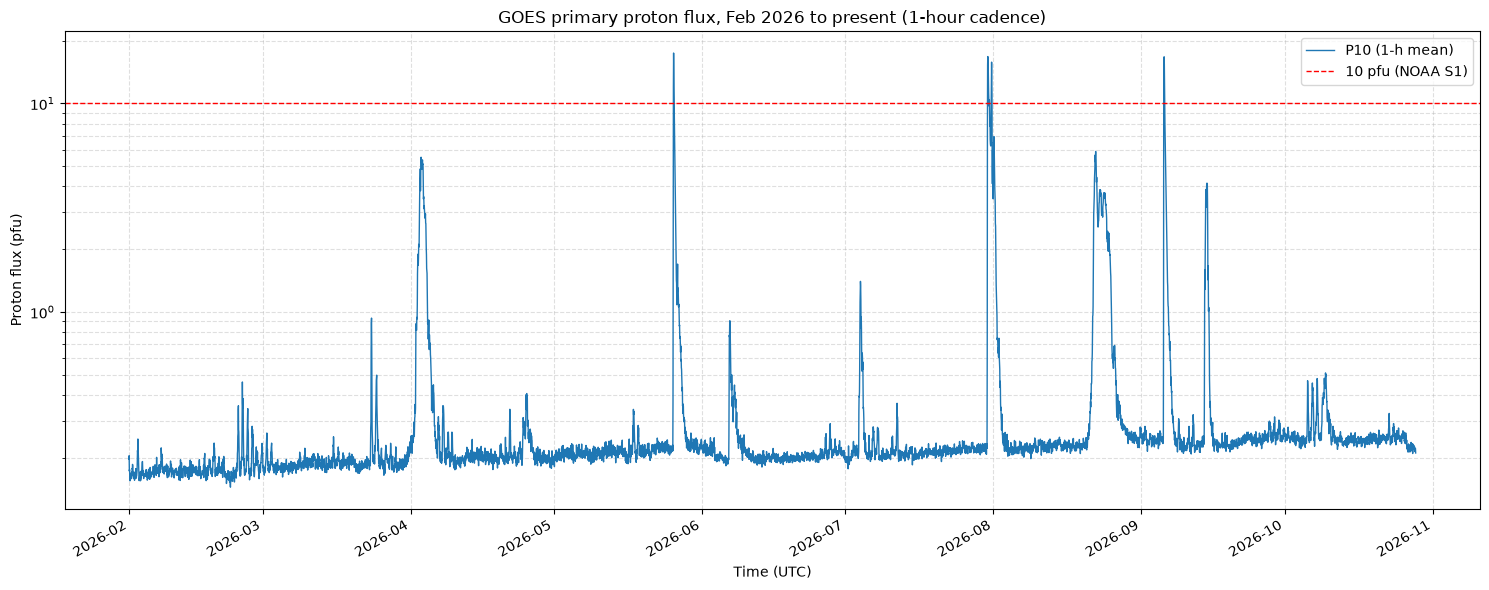

In [7]:
# ---------------------------------------------------------------- plot
fig, ax = plt.subplots(figsize=(15, 6))
for c in PLOT_COLS:
    if c not in hourly.columns:
        raise KeyError(f"{c} not in dataset; choose from {list(hourly.columns)}")
    ax.plot(hourly.index, hourly[c], lw=1, label=f"{c} (1-h mean)")

ax.axhline(10, color="red", ls="--", lw=1, label="10 pfu (NOAA S1)")
ax.set_yscale("log")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Proton flux (pfu)")
ax.set_title("GOES primary proton flux, Feb 2026 to present (1-hour cadence)")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT_DIR / "goes_proton_flux_hourly.png", dpi=200)
plt.show()

In [8]:
# get description of column contents
for p in info["parameters"]:
    print(f"{p['name']:18s} units={p.get('units')!s:12s} "
          f"fill={p.get('fill')!s:8s} | {p.get('description')}")

Time               units=UTC          fill=null     | None
P1                 units=Protons/cm^2 - s^-1 - sr fill=-100000  | None
P5                 units=Protons/cm^2 - s^-1 - sr fill=-100000  | None
P10                units=Protons/cm^2 - s^-1 - sr fill=-100000  | None
P30                units=Protons/cm^2 - s^-1 - sr fill=-100000  | None
P50                units=Protons/cm^2 - s^-1 - sr fill=-100000  | None
P100               units=Protons/cm^2 - s^-1 - sr fill=-100000  | None
E_8                units=Electrons/cm^2 - s^-1 - sr fill=-100000  | None
E2_0               units=Electrons/cm^2 - s^-1 - sr fill=-100000  | None
E4_0               units=Electrons/cm^2 - s^-1 - sr fill=-100000  | None
P60                units=Protons/cm^2 - s^-1 - sr fill=null     | None
P500               units=Protons/cm^2 - s^-1 - sr fill=null     | None
satelliteElectron  units=identifier   fill=-1       | satellited identifier for electron parameters
satelliteProton    units=identifier   fill=-1       | 

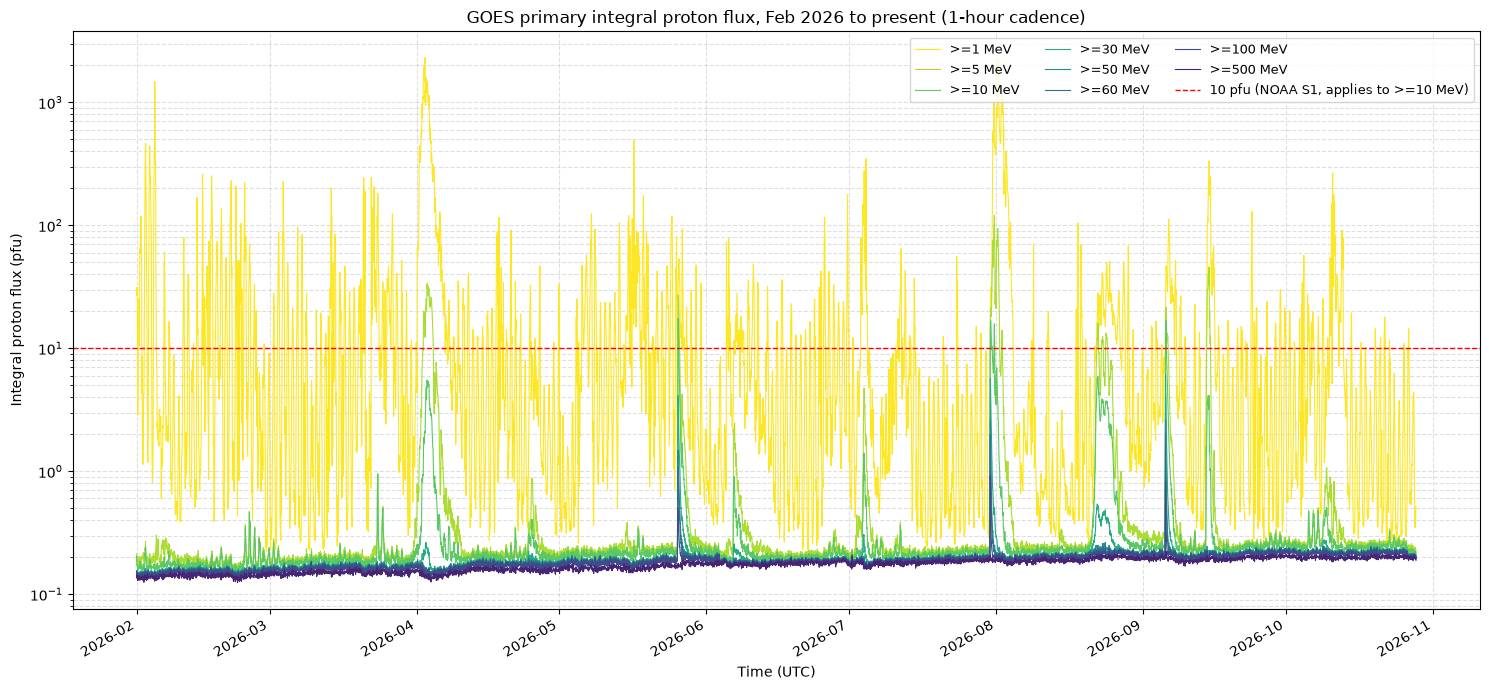

In [9]:
# ---------------------------------------------------------------- plot (all protons)
PROTON_COLS = ["P1", "P5", "P10", "P30", "P50", "P60", "P100", "P500"]
LABELS = {c: f">={c[1:]} MeV" for c in PROTON_COLS}

# P60 and P500 declare no fill value, so mask their negative placeholders
for c in ["P60", "P500"]:
    hourly.loc[hourly[c] < 0, c] = float("nan")

fig, ax = plt.subplots(figsize=(15, 7))
colors = plt.cm.viridis_r(np.linspace(0, 0.9, len(PROTON_COLS)))

for c, col in zip(PROTON_COLS, colors):
    if c not in hourly.columns:
        raise KeyError(f"{c} not in dataset; choose from {list(hourly.columns)}")
    ax.plot(hourly.index, hourly[c], lw=0.8, color=col, label=LABELS[c])

ax.axhline(10, color="red", ls="--", lw=1, label="10 pfu (NOAA S1, applies to >=10 MeV)")
ax.set_yscale("log")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Integral proton flux (pfu)")
ax.set_title("GOES primary integral proton flux, Feb 2026 to present (1-hour cadence)")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend(ncol=3, fontsize=9)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT_DIR / "goes_proton_flux_all_channels_hourly.png", dpi=200)
plt.show()

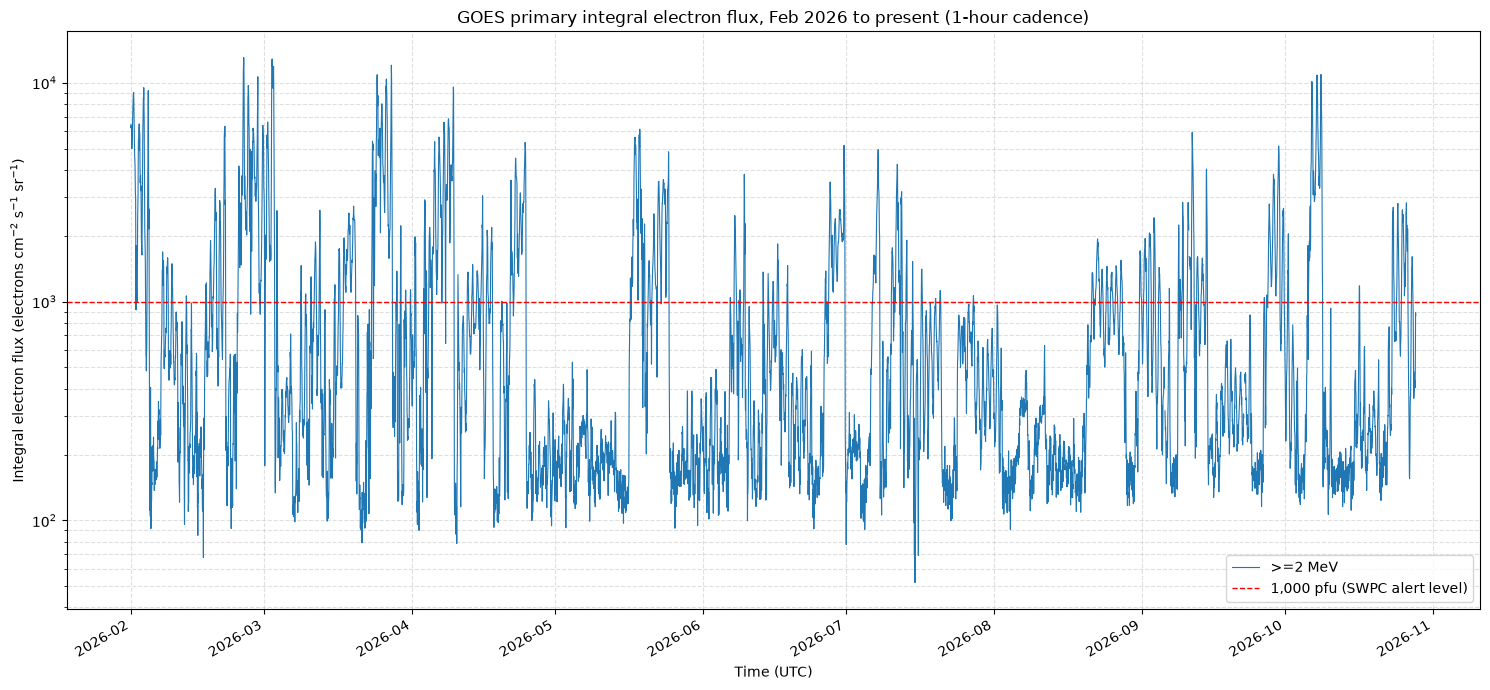

In [10]:
# ---------------------------------------------------------------- plot (electrons)
ELECTRON_COLS = ["E2_0"]
E_LABELS = {"E2_0": ">=2 MeV"}

fig, ax = plt.subplots(figsize=(15, 7))


for c in ELECTRON_COLS:
    if c not in hourly.columns:
        raise KeyError(f"{c} not in dataset; choose from {list(hourly.columns)}")
    ax.plot(hourly.index, hourly[c], lw=0.8, color="tab:blue", label=E_LABELS[c])
    
ax.axhline(1000, color="red", ls="--", lw=1, label="1,000 pfu (SWPC alert level)")
ax.set_yscale("log")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Integral electron flux (electrons cm$^{-2}$ s$^{-1}$ sr$^{-1}$)")
ax.set_title("GOES primary integral electron flux, Feb 2026 to present (1-hour cadence)")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUT_DIR / "goes_electron_flux_hourly.png", dpi=200)
plt.show()

Plot all channels, but restrict x-axis.

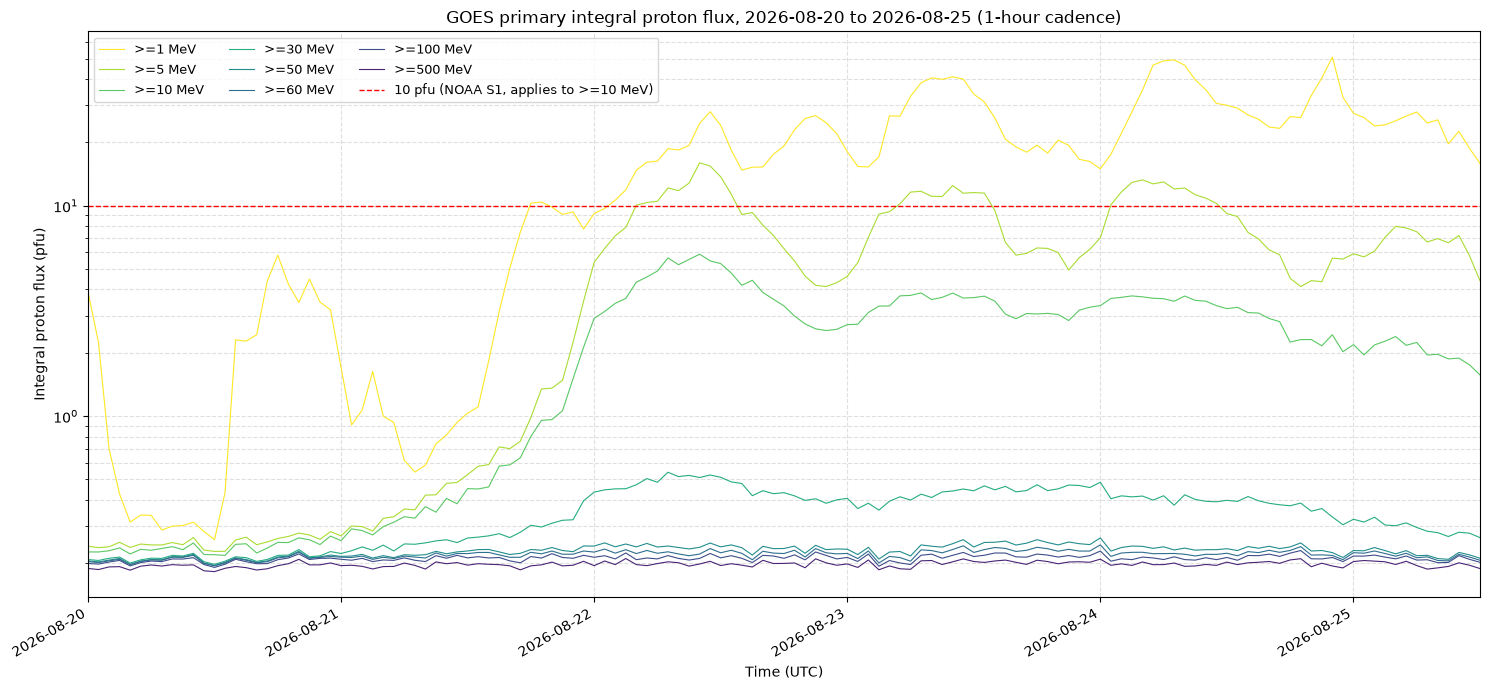

In [14]:
PROTON_COLS = ["P1", "P5", "P10", "P30", "P50", "P60", "P100", "P500"]
LABELS = {c: f">={c[1:]} MeV" for c in PROTON_COLS}

# P60 and P500 declare no fill value, so mask their negative placeholders
for c in ["P60", "P500"]:
    hourly.loc[hourly[c] < 0, c] = float("nan")


def plot_protons(df, start=None, end=None, tag="all", cadence_label="1-hour cadence"):
    """Plot integral proton flux for df[start:end].

    start/end can be partial strings: "2026-04", "2026-04-10", "2026-04-10 12:00".
    Note: label-based slicing is inclusive of `end`, and "2026-04" as an end
    covers the whole month.
    """
    sub = df.loc[start:end]
    if sub.empty:
        raise ValueError(f"No data between {start} and {end}")

    fig, ax = plt.subplots(figsize=(15, 7))
    colors = plt.cm.viridis_r(np.linspace(0, 0.9, len(PROTON_COLS)))

    for c, col in zip(PROTON_COLS, colors):
        if c not in sub.columns:
            raise KeyError(f"{c} not in dataset; choose from {list(sub.columns)}")
        ax.plot(sub.index, sub[c], lw=0.8, color=col, label=LABELS[c])

    ax.axhline(10, color="red", ls="--", lw=1,
               label="10 pfu (NOAA S1, applies to >=10 MeV)")
    ax.set_yscale("log")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Integral proton flux (pfu)")
    ax.set_title(f"GOES primary integral proton flux, "
                 f"{sub.index[0]:%Y-%m-%d} to {sub.index[-1]:%Y-%m-%d} ({cadence_label})")
    ax.set_xlim(sub.index[0], sub.index[-1])
    ax.grid(True, which="both", ls="--", alpha=0.4)
    ax.legend(ncol=3, fontsize=9)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"goes_proton_flux_{tag}_hourly.png", dpi=200)
    plt.show()


# Whole dataset (reproduces your original plot)
#plot_protons(hourly, tag="all")

# Just September 2026
#plot_protons(hourly, "2026-08", "2026-08", tag="2026-08")

# A specific event window
plot_protons(hourly, "2026-08-20", "2026-08-25 12:00", tag="2026-09-21_event")